In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("IMDb Movies India.csv", encoding="latin1")

# Display first 5 rows
df.head()

# Display dataset information
df.info()

# Display column names
df.columns.tolist()

# Display dataset size
print("Dataset shape:", df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15509 entries, 0 to 15508
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      15509 non-null  object 
 1   Year      14981 non-null  object 
 2   Duration  7240 non-null   object 
 3   Genre     13632 non-null  object 
 4   Rating    7919 non-null   float64
 5   Votes     7920 non-null   object 
 6   Director  14984 non-null  object 
 7   Actor 1   13892 non-null  object 
 8   Actor 2   13125 non-null  object 
 9   Actor 3   12365 non-null  object 
dtypes: float64(1), object(9)
memory usage: 1.2+ MB
Dataset shape: (15509, 10)


In [6]:
# Check missing values
df.isnull().sum()

# Check number of movies with ratings
print("Available ratings:", df["Rating"].notna().sum())

# Convert Year into numbers, for example "(2019)" to 2019
df["Year"] = pd.to_numeric(
    df["Year"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Convert Duration into numbers, for example "109 min" to 109
df["Duration"] = pd.to_numeric(
    df["Duration"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Remove movies without ratings
df = df.dropna(subset=["Rating"])

print("Clean dataset shape:", df.shape)

Available ratings: 7919
Clean dataset shape: (7919, 10)


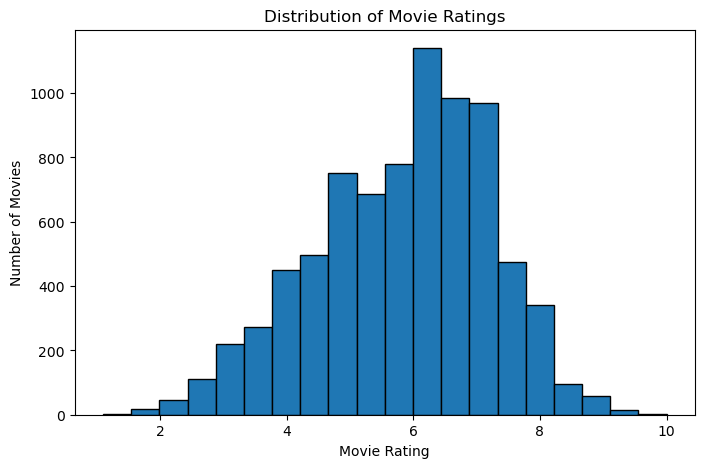

In [7]:
# Display rating statistics
df["Rating"].describe()

# Plot rating distribution
plt.figure(figsize=(8, 5))
plt.hist(df["Rating"], bins=20, edgecolor="black")
plt.title("Distribution of Movie Ratings")
plt.xlabel("Movie Rating")
plt.ylabel("Number of Movies")
plt.show()

In [8]:
features = [
    "Genre", "Director",
    "Actor 1", "Actor 2", "Actor 3",
    "Year", "Duration"
]

X = df[features]
y = df["Rating"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (7919, 7)
Target: (7919,)


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 6335
Testing records: 1584


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

categorical_features = [
    "Genre", "Director", "Actor 1", "Actor 2", "Actor 3"
]

numerical_features = ["Year", "Duration"]

# Process categorical data
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=2
    ))
])

# Process numerical data
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Combine both transformations
preprocessor = ColumnTransformer(transformers=[
    ("cat", categorical_transformer, categorical_features),
    ("num", numerical_transformer, numerical_features)
])

print("Data preprocessing completed.")

Data preprocessing completed.


In [11]:
from sklearn.linear_model import Ridge

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=10))
])

# Train the model
model.fit(X_train, y_train)

print("Movie Rating Prediction Model Trained Successfully!")

Movie Rating Prediction Model Trained Successfully!


In [12]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict test ratings
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

MAE: 0.924
RMSE: 1.175
R2 Score: 0.258


In [13]:
# New movie details
new_movie = pd.DataFrame([{
    "Genre": "Drama, Romance",
    "Director": "Sanjay Leela Bhansali",
    "Actor 1": "Ranveer Singh",
    "Actor 2": "Deepika Padukone",
    "Actor 3": "Priyanka Chopra",
    "Year": 2026,
    "Duration": 150
}])

# Predict rating
predicted_rating = model.predict(new_movie)

print("Predicted Movie Rating:", round(predicted_rating[0], 2))

Predicted Movie Rating: 6.03


In [14]:
results = pd.DataFrame({
    "Actual Rating": y_test.values,
    "Predicted Rating": y_pred
})

print(results.head(10).round(2))

   Actual Rating  Predicted Rating
0            3.3              5.06
1            5.3              5.79
2            5.7              5.18
3            7.2              6.07
4            3.5              4.58
5            7.2              5.28
6            3.8              6.04
7            6.9              5.33
8            5.2              6.03
9            7.4              6.00


In [15]:
import joblib

joblib.dump(model, "movie_rating_model.pkl")

print("Model saved successfully!")

Model saved successfully!
